# 01 · Data exploration: HAM10000

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/martinamorales/skin-lesion-triage/blob/main/notebooks/01_data_exploration.ipynb)

Before training anything, we need to understand the data. This notebook answers:

1. What does the dataset contain, and how clean is it?
2. How are the 7 diagnoses distributed? (class imbalance)
3. How was each diagnosis confirmed? (label quality)
4. How many images does each lesion have? (risk of **data leakage**)
5. Who are the patients? (age, sex, body location)
6. What do the images look like?

## Setup

On **Google Colab** this cell clones the repository and installs the project package.
Locally it just moves to the repository root. It is safe to run more than once.

In [1]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/martinamorales/skin-lesion-triage.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and Path.cwd().name != "skin-lesion-triage":
    if not Path("skin-lesion-triage").exists():
        !git clone -q {REPO_URL}
    os.chdir("skin-lesion-triage")
    !pip install -q .
elif Path.cwd().name == "notebooks":
    os.chdir("..")

print("Running on Colab:", IN_COLAB)

Running on Colab: False


Download the dataset (~2.8 GB, takes a few minutes on Colab). Files that are already
present and valid are skipped, so re-running this cell is cheap.

In [2]:
!{sys.executable} -m skin_lesion_triage.download

[skip] HAM10000_metadata.csv (already downloaded)
[skip] HAM10000_images_part_1.zip (already downloaded)
[extract] 0 new images from HAM10000_images_part_1.zip
[skip] HAM10000_images_part_2.zip (already downloaded)
[extract] 0 new images from HAM10000_images_part_2.zip
Done: 10015 images in data\ham10000\images


## 1. Loading the metadata

The metadata is a CSV file with **one row per image**. We load it with
[pandas](https://pandas.pydata.org/), the standard Python library for tabular data.
A pandas `DataFrame` is like a spreadsheet: named columns, one row per record.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("data/ham10000")
IMAGES_DIR = DATA_DIR / "images"

meta = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")
print(f"{len(meta):,} rows x {meta.shape[1]} columns")
meta.head()

10,015 rows x 8 columns


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


| Column | Meaning |
|---|---|
| `lesion_id` | Identifier of the **lesion** (the same lesion can have several images) |
| `image_id` | Identifier of the **image** (= file name in `images/`) |
| `dx` | Diagnosis (our target label) |
| `dx_type` | How the diagnosis was confirmed |
| `age`, `sex`, `localization` | Patient and lesion information |
| `dataset` | Source sub-collection (different clinics / acquisition periods) |

### Data quality checks

Every analysis starts by checking for missing values and duplicates. Note that this
dataset encodes some missing values as the string `"unknown"` instead of leaving the
cell empty, so `isna()` alone would miss them.

In [4]:
quality = pd.DataFrame({
    "missing (NaN)": meta.isna().sum(),
    'value "unknown"': (meta == "unknown").sum(),
})
print("Duplicated image ids:", meta["image_id"].duplicated().sum())
print("Images on disk:", sum(1 for _ in IMAGES_DIR.glob("*.jpg")))
quality

Duplicated image ids: 0


Images on disk: 10015


,missing (NaN),"value ""unknown"""
lesion_id,0,0
image_id,0,0
dx,0,0
dx_type,0,0
age,57,0
sex,0,57
localization,0,234
dataset,0,0


## Plot style

A small helper so every chart in the project looks the same: one color for a single
series, recessive axes and gridlines, and values printed at the end of each bar.

In [5]:
BAR_COLOR = "#2a78d6"
TEXT = "#0b0b0b"
TEXT_MUTED = "#52514e"
GRID = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "font.size": 10,
})


def barh(values: pd.Series, title: str, xlabel: str, fmt: str = "{:,.0f}"):
    """Horizontal bar chart, largest bar on top, with the value at each bar tip."""
    values = values.sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(values) + 1))
    bars = ax.barh(values.index, values.values, height=0.6, color=BAR_COLOR)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values.values],
                 padding=4, color=TEXT_MUTED)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.xaxis.grid(True, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.margins(x=0.12)
    plt.show()

## 2. Diagnoses: a highly imbalanced dataset

The `dx` column uses short codes. We map them to readable names.

In [6]:
DX_NAMES = {
    "nv": "Melanocytic nevus",
    "mel": "Melanoma",
    "bkl": "Benign keratosis",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratosis / Bowen's",
    "vasc": "Vascular lesion",
    "df": "Dermatofibroma",
}
meta["diagnosis"] = meta["dx"].map(DX_NAMES)

dx_counts = meta["diagnosis"].value_counts()
dx_table = pd.DataFrame({
    "images": dx_counts,
    "share": (dx_counts / len(meta)).map("{:.1%}".format),
})
dx_table

,images,share
diagnosis,,
Melanocytic nevus,6705,66.9%
Melanoma,1113,11.1%
Benign keratosis,1099,11.0%
Basal cell carcinoma,514,5.1%
Actinic keratosis / Bowen's,327,3.3%
Vascular lesion,142,1.4%
Dermatofibroma,115,1.1%


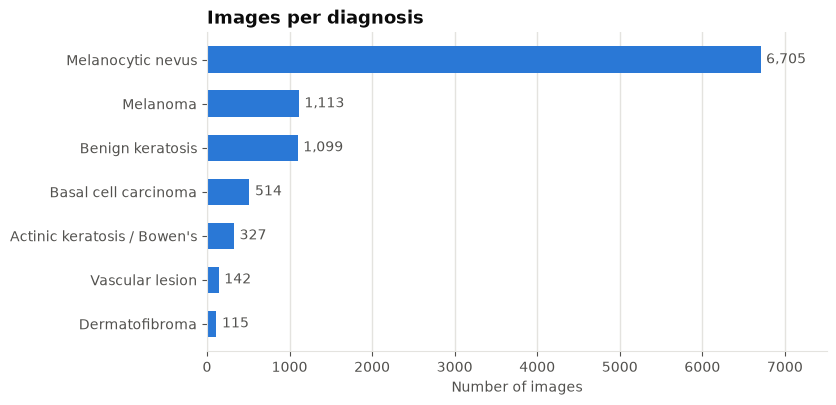

In [7]:
barh(dx_counts, "Images per diagnosis", "Number of images")

**Why this matters:** a model that *always* answers "melanocytic nevus" would already
reach an accuracy equal to the nevus share above, without learning anything.
That is why accuracy is a misleading metric here; we will use metrics such as
balanced accuracy, per-class recall and AUROC instead.

## 3. How was each diagnosis confirmed?

Not all labels are equally reliable. `dx_type` tells us how the ground truth was obtained:

- `histo`: histopathology (biopsy), the gold standard
- `follow_up`: the lesion did not change over follow-up visits
- `consensus`: expert agreement, without biopsy
- `confocal`: in-vivo confocal microscopy

`pd.crosstab` counts how often each combination of two columns appears.
`normalize="index"` turns each row into percentages.

In [8]:
(pd.crosstab(meta["diagnosis"], meta["dx_type"], normalize="index")
   .mul(100).round(1)
   .loc[dx_counts.index])

dx_type,confocal,consensus,follow_up,histo
diagnosis,,,,
Melanocytic nevus,0.0,7.5,55.2,37.3
Melanoma,0.0,0.0,0.0,100.0
Benign keratosis,6.3,24.0,0.0,69.7
Basal cell carcinoma,0.0,0.0,0.0,100.0
Actinic keratosis / Bowen's,0.0,0.0,0.0,100.0
Vascular lesion,0.0,52.8,0.0,47.2
Dermatofibroma,0.0,52.2,0.0,47.8


## 4. Images per lesion: the data-leakage trap

Some lesions were photographed several times. If two images of the **same lesion**
end up one in the training set and the other in the test set, the model can recognise
the lesion instead of the disease, and the test score becomes overly optimistic.

`groupby("lesion_id").size()` counts how many rows (images) each lesion has.

In [9]:
images_per_lesion = meta.groupby("lesion_id").size()

print(f"Images:  {len(meta):,}")
print(f"Lesions: {meta['lesion_id'].nunique():,}")
print(f"Lesions with more than one image: {(images_per_lesion > 1).sum():,}")
print(f"Images that belong to those lesions: {images_per_lesion[images_per_lesion > 1].sum():,}")

images_per_lesion.value_counts().sort_index().rename_axis("images per lesion").to_frame("lesions")

Images:  10,015
Lesions: 7,470
Lesions with more than one image: 1,956
Images that belong to those lesions: 4,501


,lesions
images per lesion,
1,5514
2,1423
3,490
4,34
5,5
6,4


**Consequence for the next step:** the train/validation/test split must be done by
`lesion_id`, not by `image_id`, so that all images of a lesion stay in the same split.

## 5. Patients: age, sex and body location

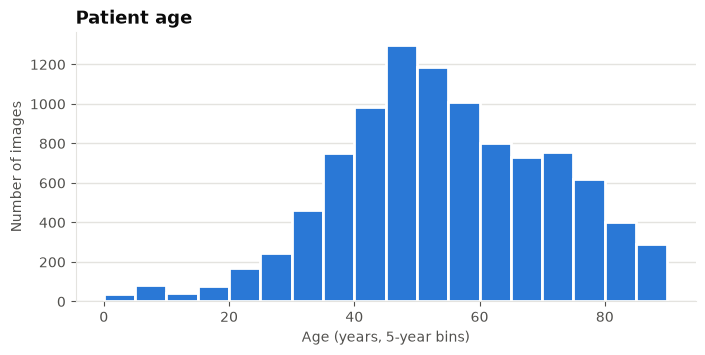

,age
count,9958.0
mean,51.9
std,17.0
min,0.0
25%,40.0
50%,50.0
75%,65.0
max,85.0


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(meta["age"].dropna(), bins=range(0, 95, 5), color=BAR_COLOR,
        edgecolor="white", linewidth=2)
ax.set_title("Patient age")
ax.set_xlabel("Age (years, 5-year bins)")
ax.set_ylabel("Number of images")
ax.yaxis.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
plt.show()

meta["age"].describe().round(1).to_frame("age")

In [11]:
meta["sex"].value_counts().to_frame("images")

,images
sex,
male,5406
female,4552
unknown,57


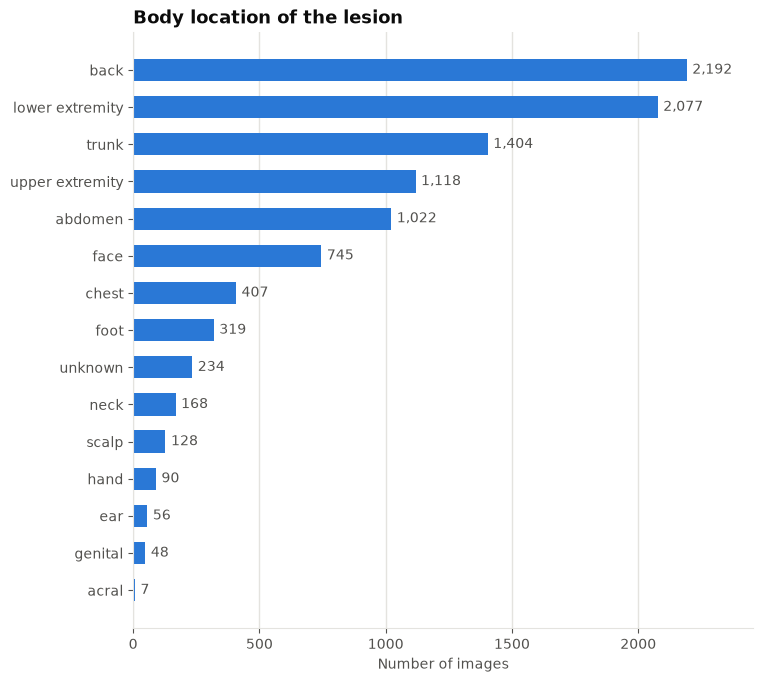

In [12]:
barh(meta["localization"].value_counts(), "Body location of the lesion", "Number of images")

**What the metadata does *not* include:** skin tone (Fitzpatrick type). The images come
from clinics in Austria and Australia, so most patients are likely to have light skin.
We cannot measure performance across skin tones with this dataset alone; that is why a
later phase evaluates the model on an external dataset.

## 6. What do the images look like?

Four random examples per diagnosis. `random_state=42` makes the "random" choice
reproducible: every run shows the same images.

Image size (width x height): (600, 450) | mode: RGB


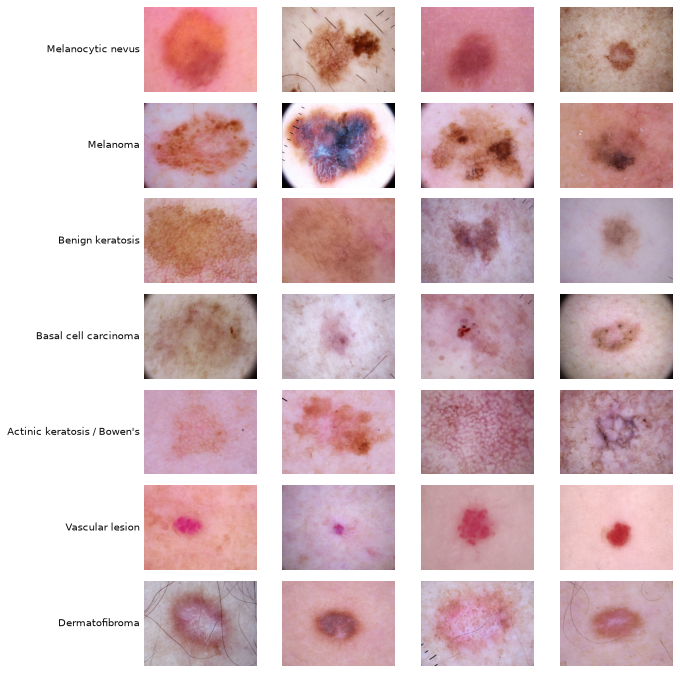

In [13]:
from PIL import Image

with Image.open(IMAGES_DIR / f"{meta['image_id'].iloc[0]}.jpg") as img:
    print("Image size (width x height):", img.size, "| mode:", img.mode)

SAMPLES = 4
# Images are 4:3, so each row is ~3/4 as tall as an image is wide. dpi=72 keeps the
# notebook file small.
fig, axes = plt.subplots(len(DX_NAMES), SAMPLES, figsize=(10, 1.35 * len(DX_NAMES)), dpi=72)
for row, diagnosis in zip(axes, dx_counts.index):
    sample = meta[meta["diagnosis"] == diagnosis].sample(SAMPLES, random_state=42)
    for ax, image_id in zip(row, sample["image_id"]):
        with Image.open(IMAGES_DIR / f"{image_id}.jpg") as img:
            ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    row[0].set_ylabel(diagnosis, rotation=0, ha="right", va="center", color=TEXT)
plt.tight_layout()
plt.show()

## Summary

| Finding | Evidence | Implication for the project |
|---|---|---|
| The data is complete and consistent | 10,015 images, all present on disk, no duplicated ids | No cleaning needed beyond handling `unknown` values |
| A few metadata values are missing | 57 missing ages, 57 unknown sex, 234 unknown locations | Fine for exploration; handle explicitly if metadata is used as input |
| **Severe class imbalance** | Nevi are 66.9% of images; dermatofibroma only 1.1% (115 images) | Accuracy is misleading → use balanced accuracy, per-class recall, AUROC |
| **Label quality differs by class** | All melanomas, BCCs and actinic keratoses are biopsy-confirmed; most nevi were confirmed by follow-up | Labels are not equally certain; worth keeping in mind when analysing errors |
| **Many images share a lesion** | 7,470 lesions; 1,956 of them have several images (4,501 images, ~45% of the dataset) | Split by `lesion_id` to avoid data leakage |
| Patients are mostly middle-aged adults | Median age 50; slightly more male than female images | Results may not transfer to children or other populations |
| No skin-tone information | Not in the metadata | Fairness across skin tones needs an external dataset |
| Images contain visual artifacts | Hair, ruler marks and dark circular borders from the dermatoscope | Possible shortcuts: the model could learn them instead of the lesion |

**Next step:** implement a lesion-level train / validation / test split, with tests that
guarantee no lesion appears in more than one split.